In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

C:\Users\adibh\anaconda3\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


In [2]:
data = pd.read_csv(r"C:\Users\adibh\Downloads\sustainable_concrete_dataset.csv")

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   cement                1000 non-null   float64
 1   water                 1000 non-null   float64
 2   superplasticizer      1000 non-null   float64
 3   coarse_aggregate      1000 non-null   float64
 4   fine_aggregate        1000 non-null   float64
 5   age                   1000 non-null   int64  
 6   compressive_strength  1000 non-null   float64
 7   embodied_CO2          1000 non-null   float64
 8   energy_consumption    1000 non-null   float64
 9   resource_consumption  1000 non-null   float64
dtypes: float64(9), int64(1)
memory usage: 78.3 KB


In [4]:
data.describe()

,cement,water,superplasticizer,coarse_aggregate,fine_aggregate,age,compressive_strength,embodied_CO2,energy_consumption,resource_consumption
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,347.076966,185.491211,15.072172,947.112514,748.231597,178.718000,226.851019,350.711848,1919.694685,2242.984460
std,87.641209,20.453293,8.720226,85.946803,86.042983,105.514424,109.089204,82.732471,436.379308,150.276497
min,201.389607,150.225279,0.000349,800.196017,600.009216,1.000000,87.828752,198.304253,1009.037338,1857.352345
25%,270.791980,166.875199,7.840529,872.570231,673.492202,84.000000,142.168353,277.670071,1559.773801,2145.539012
50%,349.042213,186.311373,15.018418,945.283785,748.379429,180.000000,189.618660,351.411465,1915.101204,2247.689282
75%,423.295876,203.232554,22.773106,1021.262243,821.998036,266.250000,288.682096,419.677749,2275.026302,2346.572861
max,499.915302,219.958961,29.934626,1099.867311,899.324817,364.000000,615.211271,507.878791,2849.195976,2652.766567


In [5]:
data.head()

,cement,water,superplasticizer,coarse_aggregate,fine_aggregate,age,compressive_strength,embodied_CO2,energy_consumption,resource_consumption
0,312.362036,162.959305,7.851171,1001.810898,771.598764,51,344.476684,307.856482,1628.413117,2256.582173
1,485.214292,187.933066,7.409364,1039.004419,841.629699,71,374.295933,468.240201,2418.001368,2561.190840
2,419.598183,211.106209,27.187637,875.140370,828.048279,48,375.110054,436.206645,2476.993640,2361.080677
3,379.597545,201.255742,7.486386,987.462230,646.169971,19,473.843719,369.537736,1928.200394,2221.971875
4,246.805592,206.459280,8.158492,971.523795,644.774841,262,132.713930,246.983875,1329.311329,2077.722000


In [6]:
data.isnull().sum()

cement                  0
water                   0
superplasticizer        0
coarse_aggregate        0
fine_aggregate          0
age                     0
compressive_strength    0
embodied_CO2            0
energy_consumption      0
resource_consumption    0
dtype: int64

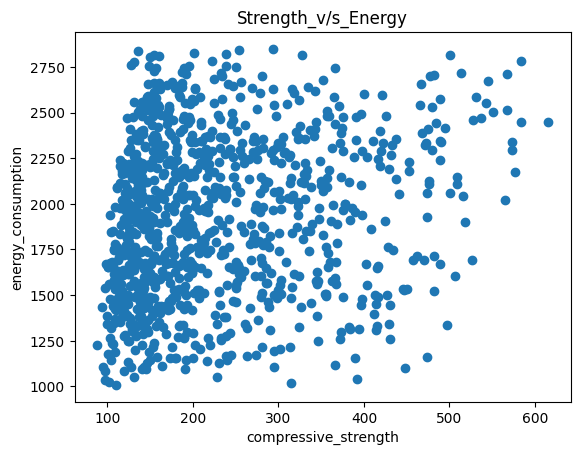

In [7]:
plt.scatter(data['compressive_strength'].values,data['energy_consumption'].values)
plt.xlabel("compressive_strength")
plt.ylabel("energy_consumption")
plt.title("Strength_v/s_Energy")
plt.show()

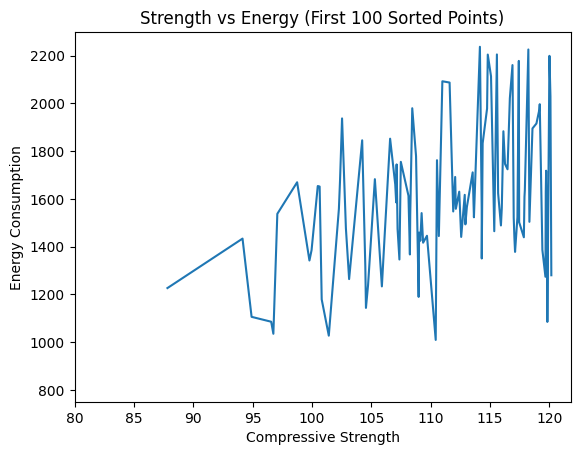

In [8]:
sorted_data = data.sort_values(by='compressive_strength', ascending=True)

subset = sorted_data.head(100)

plt.plot(subset['compressive_strength'],subset['energy_consumption'])
        
plt.xlabel("Compressive Strength")
plt.ylabel("Energy Consumption")
plt.title("Strength vs Energy (First 100 Sorted Points)")

plt.xlim(left=80)
plt.ylim(bottom=750)

plt.show()

In [9]:
X = data.drop(columns=['compressive_strength','energy_consumption']).values
Y = data[['compressive_strength','energy_consumption']].values

In [10]:
scaler = MinMaxScaler()

X = scaler.fit_transform(X)
Y = scaler.fit_transform(Y)

In [11]:
X_train, X_temp, Y_train, Y_temp = train_test_split(
    X, Y, test_size=0.3, random_state=1)

X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp, Y_temp, test_size=0.5, random_state=1)

In [12]:
model = Sequential()

model.add(Dense(8, activation='relu', input_shape=(X.shape[1],)))
model.add(Dense(10, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(8, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(2, activation='linear'))


model.compile(
    optimizer='adam',
    loss='mse'
)

C:\Users\adibh\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [13]:
early = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=200,
    batch_size=16,
    callbacks=[early]
)

Epoch 1/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.1957 - val_loss: 0.1668
Epoch 2/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1475 - val_loss: 0.1171
Epoch 3/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0909 - val_loss: 0.0519
Epoch 4/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0606 - val_loss: 0.0435
Epoch 5/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0599 - val_loss: 0.0430
Epoch 6/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0547 - val_loss: 0.0384
Epoch 7/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0513 - val_loss: 0.0354
Epoch 8/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0481 - val_loss: 0.0328
Epoch 9/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0443 - val_loss: 0.0292
Epoch 10/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0422 - val_loss: 0.0275
Epoch 11/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0373 - val_loss: 0.0230
Epoch 12/200
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.

In [14]:
def evaluate(X,Y,name):

    pred = model.predict(X)

    mse = mean_squared_error(Y,pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(Y,pred)

    print(name)
    print("MSE:",mse)
    print("RMSE:",rmse)
    print("R2:",r2)

    return pred

In [15]:
train_pred = evaluate(X_train,Y_train,"TRAIN")
val_pred   = evaluate(X_val,Y_val,"VALIDATION")
test_pred  = evaluate(X_test,Y_test,"TEST")

22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
TRAIN
MSE: 0.004612202236571736
RMSE: 0.06791319633599745
R2: 0.9060965626040172
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
VALIDATION
MSE: 0.005180166738828569
RMSE: 0.07197337520797929
R2: 0.8987173192635352
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
TEST
MSE: 0.004923289559828722
RMSE: 0.07016615679819384
R2: 0.900732389438619


In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │            90 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 806 (3.15 KB)

 Trainable params: 268 (1.05 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 538 (2.11 KB)

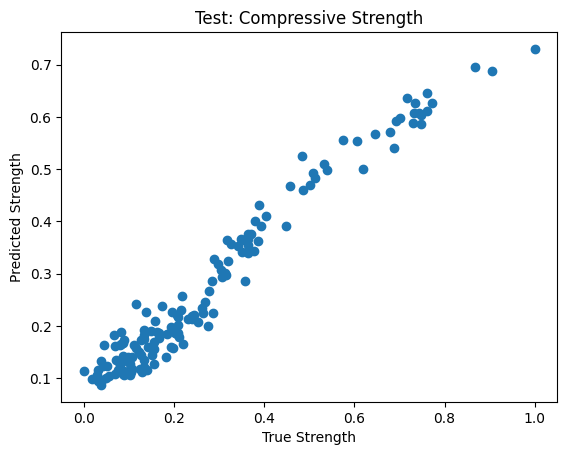

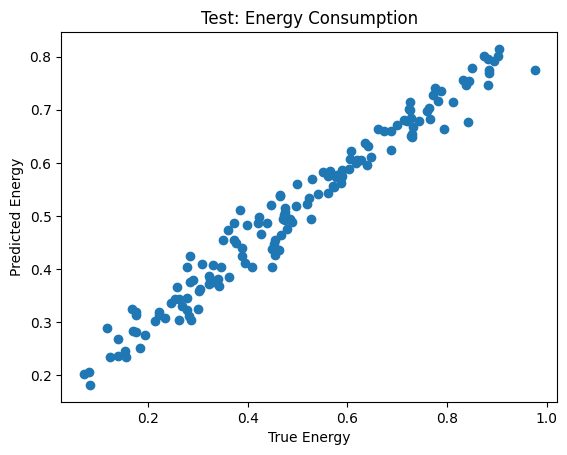

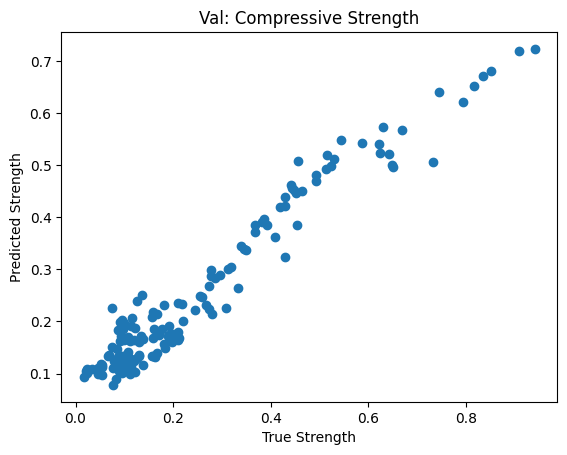

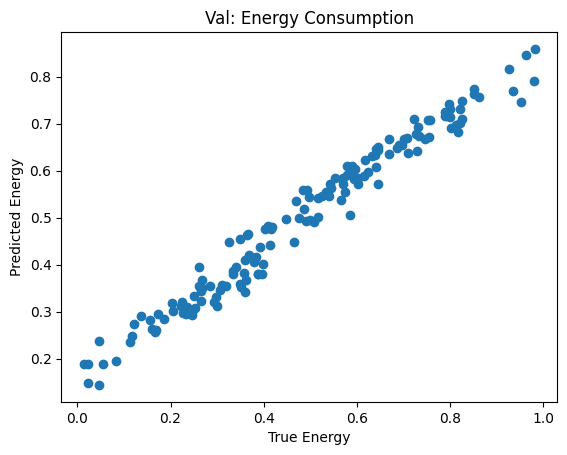

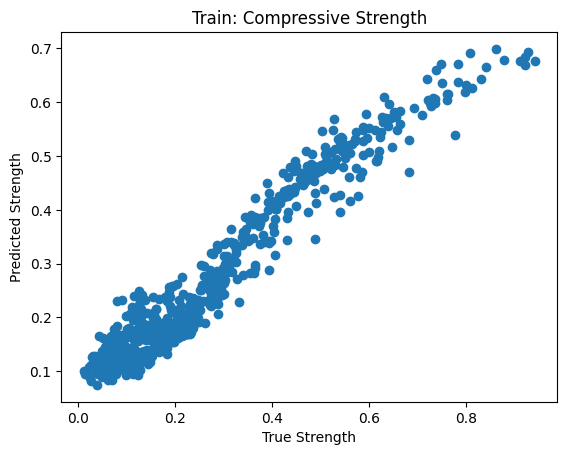

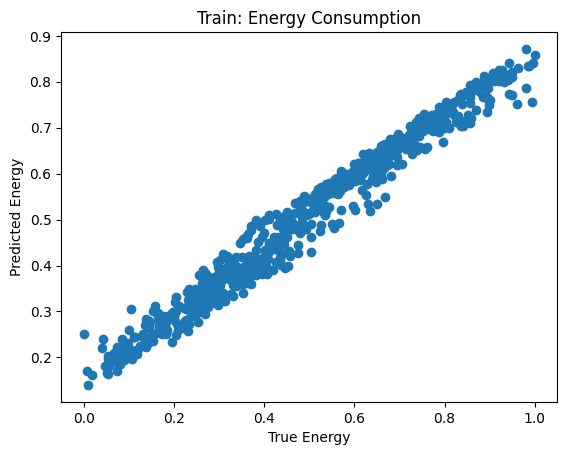

In [17]:
plt.scatter(Y_test[:,0],test_pred[:,0])
plt.xlabel("True Strength")
plt.ylabel("Predicted Strength")
plt.title("Test: Compressive Strength")
plt.show()

plt.scatter(Y_test[:,1],test_pred[:,1])
plt.xlabel("True Energy")
plt.ylabel("Predicted Energy")
plt.title("Test: Energy Consumption")
plt.show()

plt.scatter(Y_val[:,0],val_pred[:,0])
plt.xlabel("True Strength")
plt.ylabel("Predicted Strength")
plt.title("Val: Compressive Strength")
plt.show()

plt.scatter(Y_val[:,1],val_pred[:,1])
plt.xlabel("True Energy")
plt.ylabel("Predicted Energy")
plt.title("Val: Energy Consumption")
plt.show()

plt.scatter(Y_train[:,0],train_pred[:,0])
plt.xlabel("True Strength")
plt.ylabel("Predicted Strength")
plt.title("Train: Compressive Strength")
plt.show()

plt.scatter(Y_train[:,1],train_pred[:,1])
plt.xlabel("True Energy")
plt.ylabel("Predicted Energy")
plt.title("Train: Energy Consumption")
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
n_gen  |  n_eval  | n_nds  |      eps      |   indicator  
     1 |      100 |      5 |             - |             -
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
     2 |      200 |      4 |  0.1389182927 |         ideal
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
     3 |      300 |      9 |  0.0231582580 |         ideal
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
     4 |      400 |     11 |  0.0323672482 |         ideal
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
     5 |      500 |     15 |  0.0730703539 |         ideal
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
     6 |      600 |     19 |  0.0493893924 |         ideal
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
     7 |      700 |     16 |  0.0232612333 |         ideal
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
     8 |      800 |     20 |  0.0762478128 |         ideal
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
     9 |      900 |     26 |  0.0315038965 |         ideal
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
    10 |     1000 |     30 |  

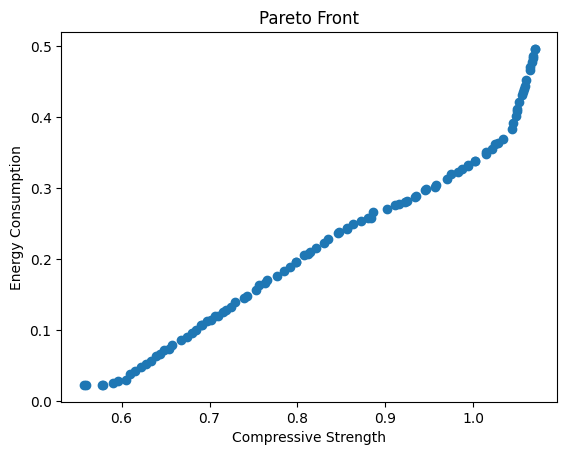

In [18]:
from pymoo.core.problem import Problem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize


class ConcreteProblem(Problem):

    def __init__(self):

        super().__init__(
            n_var=X.shape[1],
            n_obj=2,
            n_constr=0,
            xl=0,
            xu=1
        )

    def _evaluate(self,X_in,out,*args,**kwargs):

        pred = model.predict(X_in)

        strength = -pred[:,0]
        energy   = pred[:,1]

        out["F"] = np.column_stack([strength,energy])


algorithm = NSGA2(pop_size=100)


res = minimize(
    ConcreteProblem(),
    algorithm,
    ('n_gen',200),
    verbose=True
)


strength = -res.F[:,0]
energy = res.F[:,1]

plt.scatter(strength,energy)
plt.xlabel("Compressive Strength")
plt.ylabel("Energy Consumption")
plt.title("Pareto Front")
plt.show()